1. This adds the extra Python tools we need. rasterio opens satellite image files, matplotlib draws pictures, and huggingface_hub downloads from Hugging Face. Yours were already installed.

2. Asks Hugging Face for the names of every file in the dataset, then prints only the ones with “sample” in the name. It downloads nothing. It’s like reading a menu before ordering.

In [3]:

from huggingface_hub import list_repo_files
from huggingface_hub import snapshot_download
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import ListedColormap
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import segmentation_models_pytorch as smp

files = list_repo_files("links-ads/geoid-flood", repo_type="dataset")
for f in files:
    if "sample" in f:
        print(f)

assets/modality_samples.png
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-0_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-10_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-11_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-12_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-13_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-14_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-15_cloudmask_pre_20230908T101559.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-16_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-17_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-1_cloudmask_pre_20230906T102601.tif
sample/geoid-flood/EMSR712-10/cloudmask/EMSR712-10-2_cloudmask_pre_20230906T102601.tif
sample/

Downloads files to your Colab workspace. allow_patterns is the filter that keeps it small. The * means “anything here”, so sample/geoid-flood//s1grd/ means “the radar files for any event”. local_dir="data" is the folder they go into.

In [4]:
snapshot_download(
    repo_id="links-ads/geoid-flood",
    repo_type="dataset",
    allow_patterns=[
        "sample/geoid-flood/*/s1grd/*",
        "sample/geoid-flood/*/label/*",
        "sample/geoid-flood/*/validity/*",
        "sample/geoid-flood/*.csv",
    ],
    local_dir="data",
)

Fetching 189 files: 100%|██████████| 189/189 [00:29<00:00,  6.31it/s]


'/Users/arianarahmanchowdhury/Documents/skyalert/flood-model/data'

Counts the files in each folder and prints the numbers. This confirmed that everything downloaded. glob just means “find files matching this pattern”.

In [5]:
for ev in ["EMSR712-10", "EMSR712-3"]:
    for layer in ["s1grd", "label", "validity"]:
        n = len(glob.glob(f"data/sample/geoid-flood/{ev}/{layer}/*.tif"))
        print(ev, layer, n)

EMSR712-10 s1grd 36
EMSR712-10 label 18
EMSR712-10 validity 18
EMSR712-3 s1grd 58
EMSR712-3 label 29
EMSR712-3 validity 29


Draws a grid of 5 rows, where each row shows one tile as a before-flood radar picture, an after-flood radar picture, and the answer mask, so you can check that the data makes sense.

Here it is in chunks.

**Loading tools** (the import lines)

*   ```glob``` finds files by pattern.
*   ```numpy (np)``` does math on grids of numbers.
*   ```rasterio``` opens satellite image files.
*   ```matplotlib``` draws the pictures.



Choosing the tiles

```
root = "data/sample/geoid-flood/EMSR712-10"
label_files = sorted(glob.glob(f"{root}/label/*.tif"))[:5]
```

root is the folder for the first flood event. The second line lists every answer-mask file in it, puts them in order, and keeps the first 5.

Two helper tools

read(path, band=1) opens an image file and hands back one layer of it as a grid of numbers. The radar files have two layers, VV and VH, and band=1 picks VV.
to_db(x) turns raw radar numbers into decibels. The raw values are tiny and bunched together, so this spreads them out and makes the picture readable. The np.clip part stops it from taking the log of zero, which would crash.

The color key

python
cmap = ListedColormap([...])

Gray = background, blue = permanent water, orange = flooded water, black = ignore.

The empty picture grid

python
fig, axes = plt.subplots(5, 3, figsize=(10, 16))

Makes a blank canvas with 5 rows and 3 columns.

The loop (for row, lf in enumerate(label_files)) repeats these steps for each of the 5 tiles:

Get the tile’s name from the label file name (tid).
Find that tile’s matching before and after radar files.
Read all three files, converting radar to decibels.
Print how many pixels have each label value.
Draw the before, after and mask pictures in that row. np.percentile sets the brightness range so a few extreme pixels don’t wash out the image. np.where(lab == 255, 3, lab) swaps the “ignore” value 255 for 3 so it gets its own color.
Add titles, and remove the axis numbers to keep it clean.

The last two lines tidy the layout (tight_layout) and display the grid (show).

Did the plot show up for you? If so, send a screenshot and the printed label counts. We’ll check whether the orange flooded areas sit where the after image looks darker than the before image.

EMSR712-10-0 label values: {np.uint8(0): np.int64(366445), np.uint8(255): np.int64(682131)}
EMSR712-10-10 label values: {np.uint8(0): np.int64(1028743), np.uint8(1): np.int64(5028), np.uint8(2): np.int64(14805)}
EMSR712-10-11 label values: {np.uint8(0): np.int64(230678), np.uint8(255): np.int64(817898)}
EMSR712-10-12 label values: {np.uint8(0): np.int64(830605), np.uint8(1): np.int64(225), np.uint8(2): np.int64(73362), np.uint8(255): np.int64(144384)}
EMSR712-10-13 label values: {np.uint8(0): np.int64(981107), np.uint8(1): np.int64(1459), np.uint8(2): np.int64(66010)}


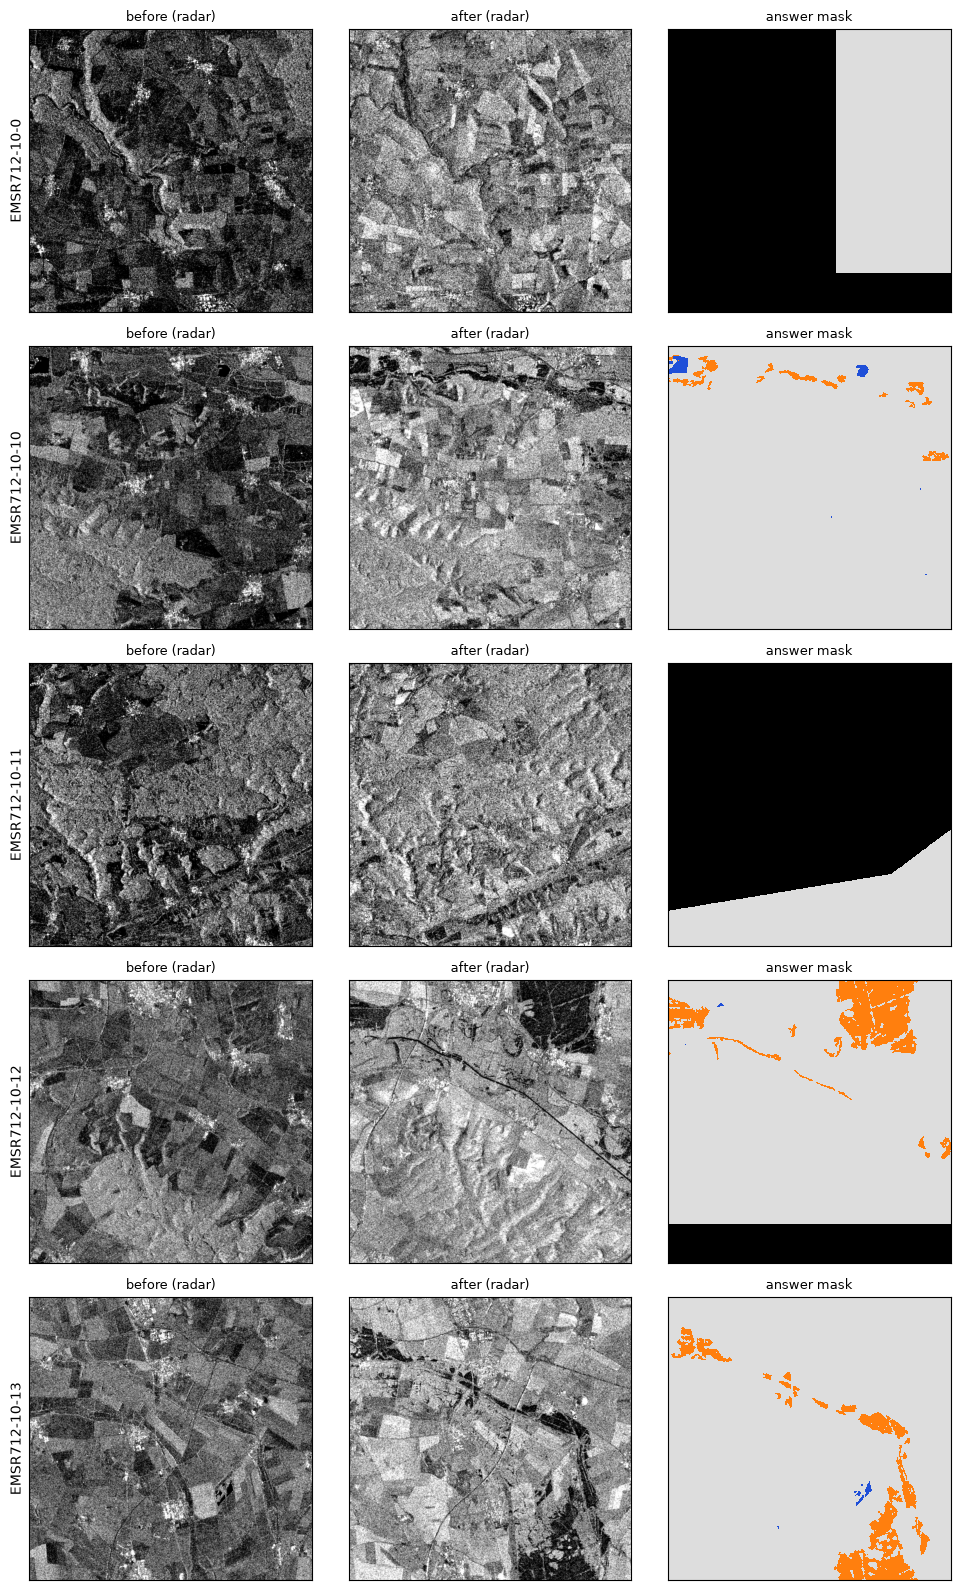

In [6]:

root = "data/sample/geoid-flood/EMSR712-10"
label_files = sorted(glob.glob(f"{root}/label/*.tif"))[:5]

def read(path, band=1):
    with rasterio.open(path) as f:
        return f.read(band).astype("float32")

def to_db(x):
    return 10 * np.log10(np.clip(x, 1e-6, None))   # radar values to decibels

# 0 background, 1 permanent water, 2 flooded water, 3 = ignore (shown for 255)
cmap = ListedColormap(["#dddddd", "#1f4fd8", "#ff7f0e", "#000000"])

fig, axes = plt.subplots(5, 3, figsize=(10, 16))
for row, lf in enumerate(label_files):
    tid = lf.split("/")[-1].split("_label")[0]
    pre = glob.glob(f"{root}/s1grd/{tid}_s1grd_pre_*.tif")[0]
    post = glob.glob(f"{root}/s1grd/{tid}_s1grd_post_*.tif")[0]

    pre_db = to_db(read(pre, 1))    # band 1 = VV
    post_db = to_db(read(post, 1))
    lab = read(lf).astype("uint8")

    print(tid, "label values:", dict(zip(*np.unique(lab, return_counts=True))))

    lo, hi = np.percentile(post_db, [2, 98])
    axes[row, 0].imshow(pre_db, cmap="gray", vmin=lo, vmax=hi)
    axes[row, 1].imshow(post_db, cmap="gray", vmin=lo, vmax=hi)
    show = np.where(lab == 255, 3, lab)
    axes[row, 2].imshow(show, cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
    axes[row, 0].set_ylabel(tid)
    for c, t in enumerate(["before (radar)", "after (radar)", "answer mask"]):
        axes[row, c].set_title(t, fontsize=9)
        axes[row, c].set_xticks([]); axes[row, c].set_yticks([])
plt.tight_layout()
plt.show()

## Phase 4: Build the model

**Goal:** create the model (a U-Net) and prepare the data so it can be fed to it. No learning happens yet. Building a model means choosing its shape and starting values (weights). Training in Phase 5 onward adjusts them.

### What we found about the data
- Each tile is **1024×1024** with **2 radar bands** (VV and VH, Sentinel-1 GRD).
- Training data: 18 tiles from event `EMSR712-10`.
- Scaling numbers (computed from training tiles only, in decibels):
  - mean: `[-7.19, -14.80]`
  - std: `[3.05, 3.82]`

### Step 1: Read the radar images
`load_radar_db(path)` opens a `.tif`, turns no-data pixels (zero or less) into NaN, and converts the values to decibels (`10 * log10`). Raw radar values are tiny and bunched together, so decibels spread them out.

### Step 2: Scale the numbers (normalize)
Neural networks learn better when inputs are centered around 0. Each band is scaled with `(value - mean) / std`. The mean and std come from **training tiles only**, then are reused for validation, test and any future input. Using test data here would leak information into training.

### Step 3: Data loader
`FloodDataset` hands the model one tile and its answer at a time.
- Input: **after-flood radar only** (VV, VH). This is the simplest first version. Before-flood radar and elevation are tested later as optional extras.
- No-data pixels become 0 (the average) after scaling.
- The label is kept as it is, including **255 = ignore**, so the loss can skip those pixels.
- Current limitation: it crops only the top-left 256×256 corner of each tile. This will be changed to random crops across the whole tile in Phase 5.

### Step 4: Create the U-Net
```python
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                 in_channels=2, classes=3)
```
- **U-Net**: a design that looks at the whole image, then colors every pixel.
- **resnet34 encoder, pretrained on ImageNet**: starts with basic knowledge of edges and shapes from ordinary photos. Radar images look different from photos, so this is a head start, not a guarantee.
- `in_channels=2`: VV and VH.
- `classes=3`: background, permanent water, flooded water.

### Check: one batch through the untrained model
| Item | Shape | Meaning |
|---|---|---|
| Input | `[4, 2, 256, 256]` | 4 chips, 2 bands, 256×256 pixels |
| Answers | `[4, 256, 256]` | one label per pixel |
| Output | `[4, 3, 256, 256]` | 3 scores per pixel, one per class |

Device: `cuda` (GPU is on). The output scores are random guesses because nothing has been trained.

### Draft model contract (so far)
- Sensor: Sentinel-1 radar (GRD)
- Input mode: after-flood image only
- Bands: band 1 = VV, band 2 = VH (to be confirmed from the file's band names)
- Scaling: per-band mean and std from training tiles (values above)
- Labels: 0 background, 1 permanent water, 2 flooded water, 255 ignore
- Model: U-Net, resnet34 encoder, ImageNet start

In [7]:
def load_radar_db(path):
    with rasterio.open(path) as f:
        x = f.read().astype("float32")      # shape [bands, H, W]
    x[x <= 0] = np.nan                       # no-data pixels become NaN
    return 10 * np.log10(x)                  # decibels

p = sorted(glob.glob("data/sample/geoid-flood/EMSR712-10/s1grd/*post*.tif"))[0]
print(load_radar_db(p).shape)

train_dir = "data/sample/geoid-flood/EMSR712-10"
posts = sorted(glob.glob(f"{train_dir}/s1grd/*_post_*.tif"))
stack = np.stack([load_radar_db(p) for p in posts])   # [tiles, bands, H, W]
mean = np.nanmean(stack, axis=(0, 2, 3))
std = np.nanstd(stack, axis=(0, 2, 3))
print("mean:", mean, "std:", std)

class FloodDataset(Dataset):
    def __init__(self, event_dirs, mean, std, size=256):
        self.items, self.size = [], size
        self.mean = np.array(mean, dtype="float32")[:, None, None]
        self.std = np.array(std, dtype="float32")[:, None, None]
        for ev in event_dirs:
            for lf in sorted(glob.glob(f"{ev}/label/*.tif")):
                tid = lf.split("/")[-1].split("_label")[0]
                post = glob.glob(f"{ev}/s1grd/{tid}_s1grd_post_*.tif")[0]
                self.items.append((post, lf, tid))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        post, lf, tid = self.items[i]
        x = (load_radar_db(post) - self.mean) / self.std
        x = np.nan_to_num(x, nan=0.0)            # no-data -> 0 (the average)
        with rasterio.open(lf) as f:
            y = f.read(1).astype("int64")        # keeps 255 = ignore
        s = self.size
        x, y = x[:, :s, :s], y[:s, :s]
        assert x.shape[1:] == (s, s), f"{tid} is smaller than {s}"
        return torch.from_numpy(x), torch.from_numpy(y), tid

train_ds = FloodDataset([train_dir], mean, std)
print(len(train_ds), "training tiles")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",   # start from the pretrained photo knowledge
    in_channels=2,                # VV and VH
    classes=3,                    # background, permanent water, flooded water
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
print("device:", device)

loader = DataLoader(train_ds, batch_size=4, shuffle=True)
x, y, ids = next(iter(loader))
with torch.no_grad():
    out = model(x.to(device))
print(x.shape, y.shape, out.shape)

def load_radar_db(path):
    with rasterio.open(path) as f:
        x = f.read().astype("float32")      # shape [bands, H, W]
    x[x <= 0] = np.nan                       # no-data pixels become NaN
    return 10 * np.log10(x)                  # decibels

p = sorted(glob.glob("data/sample/geoid-flood/EMSR712-10/s1grd/*post*.tif"))[0]
print(load_radar_db(p).shape)


(2, 1024, 1024)
mean: [ -7.1943674 -14.803526 ] std: [3.0502045 3.8224514]
18 training tiles
device: cpu
torch.Size([4, 2, 256, 256]) torch.Size([4, 256, 256]) torch.Size([4, 3, 256, 256])
(2, 1024, 1024)


## Phase 5: Tiny test (can the model memorize 5 chips?)

**Goal:** check that the pipeline works before real training. We train the model on only 5 image chips and try to make it memorize them. If it cannot, something is broken (labels, scaling, shapes). Passing this test does **not** show the model works on new floods. That is tested later with validation and test data.

### Step 1: Choose the 5 chips
- From the 18 training tiles, take the 5 chips (256×256) with the most flood pixels (label 2).
- Tiles with no flood labels (such as tiles 0 and 11) are skipped.
- The crop is picked by searching the whole 1024×1024 tile, not just the top-left corner as in Phase 4.
- Input: after-flood radar (VV, VH), scaled with the training mean and std from Phase 4.
- Expected shapes: input `[5, 2, 256, 256]`, labels `[5, 256, 256]`.
- Note: choosing the floodiest chips is fine for this test only. Real training will use random crops.

### Step 2: Loss and optimizer
- **Loss: cross-entropy with `ignore_index=255`.** It scores how wrong the model's guess is for each pixel. The 255 (ignore) pixels are skipped, since they have no real answer.
- **Optimizer: Adam, learning rate 1e-3.** After each round it adjusts the model's weights to lower the loss.
- The model is created fresh in this cell (U-Net, resnet34 encoder, ImageNet start), so rerunning the cell starts over.

### Step 3: Train
- 200 rounds (epochs) on the same 5 chips, all at once.
- Each round: guess → compute loss → work out how to adjust (`loss.backward()`) → update the weights (`opt.step()`).
- The loss is printed every 20 rounds and saved for a plot.

### Step 4: Check the result
- **Flood IoU on the 5 chips:** overlap between predicted flood and true flood, ignoring label 255 pixels. 1.0 is perfect overlap and 0 is none.
- A picture for each chip: radar (VH), truth mask, predicted mask.
- A plot of loss against round.

### Pass or fail
| Result | Meaning |
|---|---|
| Loss falls steadily toward 0, flood IoU is high (aim for above 0.9), predictions look like truth | **Pass.** The pipeline works. |
| Loss stays flat, or flood IoU stays near 0 | **Fail.** Check the points below. |

If it fails, check in order:
1. Do the chips really contain flood pixels? (`(Y == 2).sum()`)
2. Is `device` `cuda`?
3. Are the inputs scaled? (most values should be between about -3 and 3)
4. Does the label match the radar chip? (compare the picture)

### Results (fill in after running)
- Chips used: _______________
- Flood pixels per chip: _______________
- Final loss: _______________
- Flood IoU on the 5 chips: _______________
- Pass or fail: _______________
- Notes: _______________

### What this does not tell us
The model has seen these 5 chips hundreds of times, so a good score only shows it can learn. It says nothing yet about floods it has not seen. Generalization is measured in the validation and test phases using separate events.

EMSR712-10-12 crop at (0, 640) flood pixels: 51141
EMSR712-10-7 crop at (128, 0) flood pixels: 45435
EMSR712-10-13 crop at (768, 640) flood pixels: 29951
EMSR712-10-9 crop at (0, 768) flood pixels: 10271
EMSR712-10-15 crop at (640, 0) flood pixels: 5081
torch.Size([5, 2, 256, 256]) torch.Size([5, 256, 256])
0 2.0296
20 0.2308
40 0.0916
60 0.054
80 0.039
100 0.0294
120 0.024
140 0.0201
160 0.017
180 0.0145
final loss: 0.0136
flood IoU on the 5 chips: 0.993


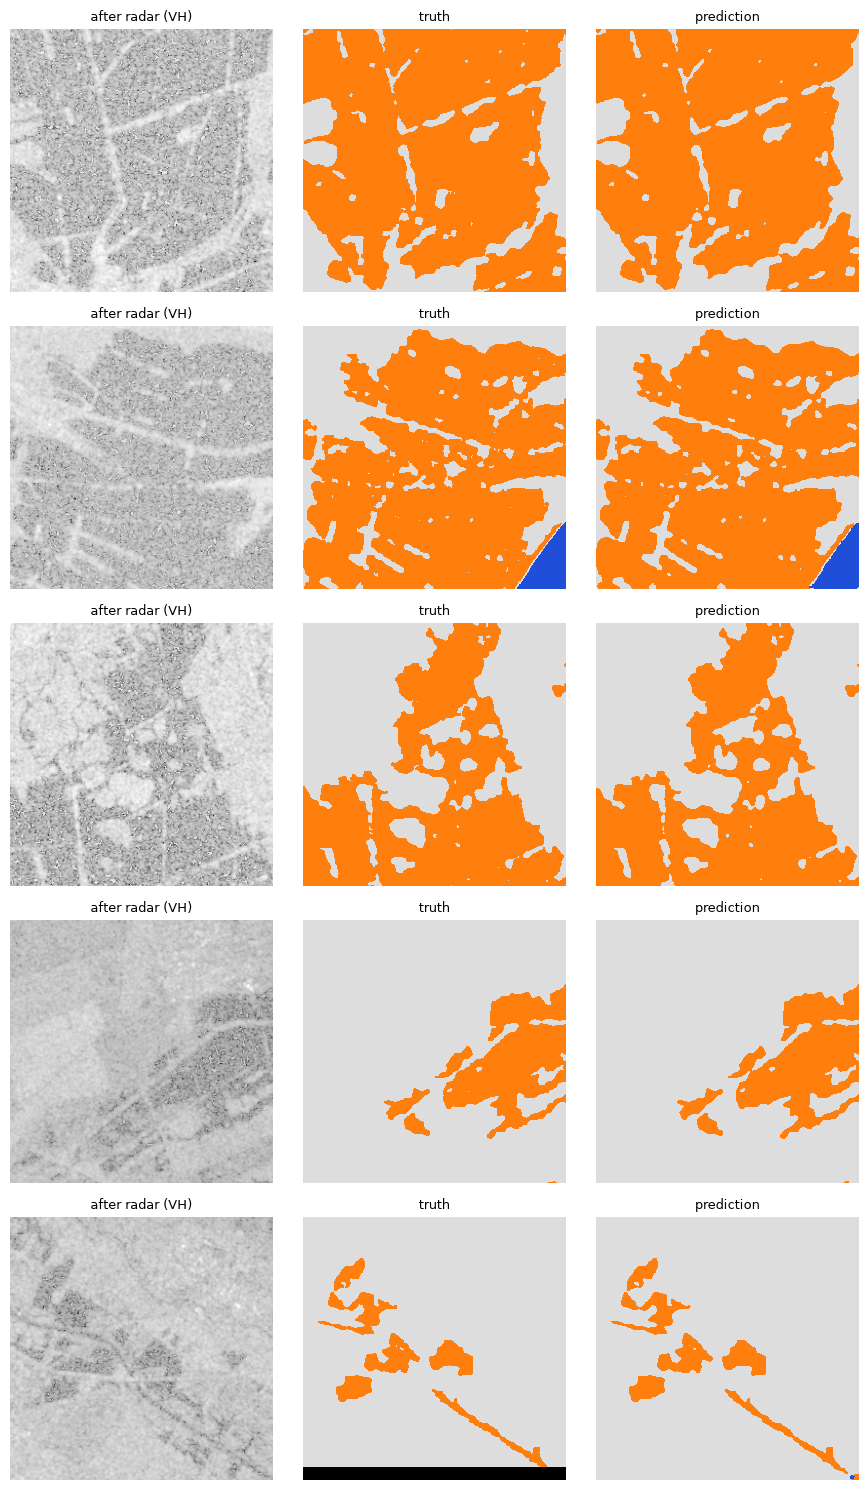

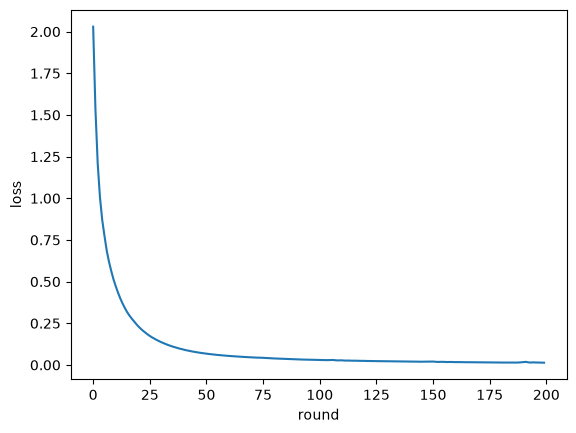

In [8]:
def read_label(lf):
    with rasterio.open(lf) as f:
        return f.read(1).astype("int64")

def best_crop(y, size=256, stride=128):
    best, pos = -1, (0, 0)
    for r in range(0, y.shape[0] - size + 1, stride):
        for c in range(0, y.shape[1] - size + 1, stride):
            n = (y[r:r+size, c:c+size] == 2).sum()
            if n > best:
                best, pos = n, (r, c)
    return pos, best

cands = []
for lf in sorted(glob.glob(f"{train_dir}/label/*.tif")):
    pos, n = best_crop(read_label(lf))
    cands.append((n, lf, pos))
cands.sort(reverse=True)
chosen = cands[:5]

xs, ys = [], []
for n, lf, (r, c) in chosen:
    tid = lf.split("/")[-1].split("_label")[0]
    post = glob.glob(f"{train_dir}/s1grd/{tid}_s1grd_post_*.tif")[0]
    x = (load_radar_db(post) - mean[:, None, None]) / std[:, None, None]
    x = np.nan_to_num(x, nan=0.0)
    xs.append(x[:, r:r+256, c:c+256])
    ys.append(read_label(lf)[r:r+256, c:c+256])
    print(tid, "crop at", (r, c), "flood pixels:", n)

X = torch.from_numpy(np.stack(xs)).float().to(device)
Y = torch.from_numpy(np.stack(ys)).to(device)
print(X.shape, Y.shape)

model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                 in_channels=2, classes=3).to(device)
loss_fn = nn.CrossEntropyLoss(ignore_index=255)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []
for epoch in range(200):
    model.train()
    opt.zero_grad()
    loss = loss_fn(model(X), Y)
    loss.backward()
    opt.step()
    losses.append(loss.item())
    if epoch % 20 == 0:
        print(epoch, round(loss.item(), 4))
print("final loss:", round(losses[-1], 4))

model.eval()
with torch.no_grad():
    pred = model(X).argmax(1)

valid = Y != 255
p, t = (pred == 2) & valid, (Y == 2) & valid
iou = (p & t).sum().item() / max((p | t).sum().item(), 1)
print("flood IoU on the 5 chips:", round(iou, 3))

cmap = ListedColormap(["#dddddd", "#1f4fd8", "#ff7f0e", "#000000"])
fig, axes = plt.subplots(5, 3, figsize=(9, 15))
for i in range(5):
    axes[i, 0].imshow(X[i, 1].cpu(), cmap="gray")
    axes[i, 1].imshow(np.where(Y[i].cpu() == 255, 3, Y[i].cpu()),
                      cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
    axes[i, 2].imshow(pred[i].cpu(), cmap=cmap, vmin=0, vmax=3,
                      interpolation="nearest")
    for c, name in enumerate(["after radar (VH)", "truth", "prediction"]):
        axes[i, c].set_title(name, fontsize=9); axes[i, c].axis("off")
plt.tight_layout(); plt.show()

plt.plot(losses); plt.xlabel("round"); plt.ylabel("loss"); plt.show()